# Cross-Corpora Analysis

Takes every per-run CSV in `../results/` (one per paradigm:
`BinaryOriginal`, `BinaryTomek`, `multiOriginal`, `multiTomek`,
`aggregate`) and does two things:

1. **Permutation / Wilcoxon significance** — pick any paradigm pair
   (A = baseline, B = comparison) and a metric (micro-F1 or macro-F1)
   from the dropdowns. For each (model, dataset) we run a paired
   Wilcoxon signed-rank test (paired by seed) with Benjamini-Hochberg
   FDR correction across the whole table; the resulting
   `significant_bh` column flags cells where B > A at BH p < 0.05.
   The bars under the table show the two means per model with
   ★ markers over significant rows — same pattern as
   `aggregate_vs_baseline.ipynb` §5.
2. **Model ranking across all paradigms × datasets** — same recipe
   as `results_analysis.ipynb` §6/§7, but the ranking is pooled over
   every (paradigm, dataset) experiment instead of a single CSV.

In [1]:
from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import ipywidgets as widgets
from IPython.display import display, clear_output

sns.set_style('whitegrid')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)

RESULTS_DIR = Path('../results').resolve()
if not RESULTS_DIR.exists():
    RESULTS_DIR = Path('results').resolve()
RESULTS_DIR

PosixPath('/Users/basel.alshaikhdeeb/medre-bench/results')

## 0. Load every paradigm CSV

In [2]:
def _clean(df: pd.DataFrame) -> pd.DataFrame:
    # Drop pandas' unnamed index column if present
    df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
    # Normalize seed to string so paired-by-seed works regardless of dtype
    if 'seed' in df.columns:
        df['seed'] = df['seed'].astype(str)
    return df

paradigm_csvs = sorted(RESULTS_DIR.glob('*.csv'))
paradigms = {p.stem: _clean(pd.read_csv(p)) for p in paradigm_csvs}

print(f'Loaded {len(paradigms)} paradigm CSV(s) from {RESULTS_DIR}')
for name, d in paradigms.items():
    print(f'  {name:20s}  rows={len(d):4d}  '
          f'models={d["model"].nunique():2d}  '
          f'datasets={d["dataset"].nunique():2d}  '
          f'seeds={d["seed"].nunique():2d}')

Loaded 6 paradigm CSV(s) from /Users/basel.alshaikhdeeb/medre-bench/results
  BinaryOriginal        rows= 640  models=16  datasets= 8  seeds= 5
  BinaryTomek           rows= 641  models=16  datasets= 8  seeds= 5
  aggregate_binary      rows= 560  models=16  datasets= 7  seeds= 5
  aggregate_multiclass  rows= 559  models=16  datasets= 7  seeds= 5
  multiOriginal         rows= 640  models=16  datasets= 8  seeds= 5
  multiTomek            rows= 642  models=16  datasets= 8  seeds= 5


## 1. Permutation / Wilcoxon significance

For each `(model, dataset)` cell we take the per-seed metric values
from paradigm **A** and paradigm **B**:

- **Paired by seed** whenever ≥ 2 seeds overlap: Wilcoxon signed-rank
  (one-sided, `B > A`) + paired t-test + paired Cohen's $d$.
- **Unpaired fallback** when seeds don't align: Mann-Whitney U
  (one-sided) + Welch's t-test + independent Cohen's $d$.

All p-values are BH-FDR-corrected across the entire table.
`significant_bh = True` → B is reliably better than A at BH p < 0.05.

In [3]:
def _bh_adjust(pvals):
    """Benjamini-Hochberg FDR-adjusted p-values."""
    m = len(pvals)
    if m == 0:
        return []
    order = np.argsort(pvals)
    ranked = np.array(pvals)[order]
    adj = ranked * m / (np.arange(m) + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    adj = np.clip(adj, 0, 1)
    out = np.empty(m)
    out[order] = adj
    return out.tolist()


def _cohens_d_paired(a, b):
    diffs = np.array(a) - np.array(b)
    if len(diffs) < 2 or np.std(diffs, ddof=1) == 0:
        return np.nan
    return float(np.mean(diffs) / np.std(diffs, ddof=1))


def _cohens_d_indep(a, b):
    if len(a) < 2 or len(b) < 2:
        return np.nan
    pooled = np.sqrt(((len(a) - 1) * np.var(a, ddof=1)
                      + (len(b) - 1) * np.var(b, ddof=1))
                     / (len(a) + len(b) - 2))
    if pooled == 0:
        return np.nan
    return float((np.mean(a) - np.mean(b)) / pooled)


def _row_sig(a_vals, a_seeds, b_vals, b_seeds):
    """One-sided test B > A, paired-by-seed when ≥ 2 overlap."""
    if len(a_vals) < 2 or len(b_vals) < 2:
        return {'pairing': 'insufficient',
                'n': min(len(a_vals), len(b_vals)),
                'wilcoxon_p': np.nan, 'ttest_p': np.nan, 'cohens_d': np.nan}
    shared = sorted(set(a_seeds) & set(b_seeds))
    if len(shared) >= 2:
        a_map = dict(zip(a_seeds, a_vals))
        b_map = dict(zip(b_seeds, b_vals))
        a = [a_map[s] for s in shared]
        b = [b_map[s] for s in shared]
        diffs = np.array(b) - np.array(a)
        if np.all(diffs == 0):
            return {'pairing': 'paired', 'n': len(shared),
                    'wilcoxon_p': 1.0, 'ttest_p': 1.0, 'cohens_d': 0.0}
        try:
            wp = float(stats.wilcoxon(b, a, alternative='greater',
                                      zero_method='wilcox').pvalue)
        except ValueError:
            wp = np.nan
        try:
            tp = float(stats.ttest_rel(b, a, alternative='greater').pvalue)
        except Exception:
            tp = np.nan
        return {'pairing': 'paired', 'n': len(shared),
                'wilcoxon_p': wp, 'ttest_p': tp,
                'cohens_d': _cohens_d_paired(b, a)}
    u = stats.mannwhitneyu(b_vals, a_vals, alternative='greater')
    try:
        tp = float(stats.ttest_ind(b_vals, a_vals, alternative='greater',
                                   equal_var=False).pvalue)
    except Exception:
        tp = np.nan
    return {'pairing': 'unpaired',
            'n': f'{len(b_vals)}v{len(a_vals)}',
            'wilcoxon_p': float(u.pvalue), 'ttest_p': tp,
            'cohens_d': _cohens_d_indep(b_vals, a_vals)}


def build_sig_table(df_a: pd.DataFrame, df_b: pd.DataFrame,
                    metric_col: str) -> pd.DataFrame:
    """Per-(model, dataset) significance table with BH-adjusted p-values."""
    models = sorted(set(df_a['model']) & set(df_b['model']))
    datasets = sorted(set(df_a['dataset']) & set(df_b['dataset']))
    rows = []
    for model in models:
        for ds in datasets:
            a_sub = df_a[(df_a['model'] == model) & (df_a['dataset'] == ds)]
            b_sub = df_b[(df_b['model'] == model) & (df_b['dataset'] == ds)]
            a_vals = a_sub[metric_col].dropna().tolist()
            b_vals = b_sub[metric_col].dropna().tolist()
            a_seeds = a_sub['seed'].tolist()
            b_seeds = b_sub['seed'].tolist()
            a_mean = float(np.mean(a_vals)) if a_vals else np.nan
            b_mean = float(np.mean(b_vals)) if b_vals else np.nan
            a_std = float(np.std(a_vals, ddof=1)) if len(a_vals) > 1 else 0.0
            b_std = float(np.std(b_vals, ddof=1)) if len(b_vals) > 1 else 0.0
            sig = _row_sig(a_vals, a_seeds, b_vals, b_seeds)
            rows.append({
                'model': model, 'dataset': ds,
                'A_mean': a_mean, 'A_std': a_std,
                'B_mean': b_mean, 'B_std': b_std,
                'delta': b_mean - a_mean if pd.notna(a_mean) and pd.notna(b_mean) else np.nan,
                **sig,
            })
    out = pd.DataFrame(rows)
    if out.empty:
        return out
    out['wilcoxon_p_bh'] = _bh_adjust(out['wilcoxon_p'].fillna(1.0).tolist())
    out['ttest_p_bh'] = _bh_adjust(out['ttest_p'].fillna(1.0).tolist())
    out['significant_bh'] = out['wilcoxon_p_bh'] < 0.05
    return out

### Pick a paradigm pair + metric

`A` is the baseline; `B` is the comparison. The test asks
"is B significantly better than A for this (model, dataset) cell?"
Hit **Run** to recompute the table and plot.

In [13]:
paradigm_names = sorted(paradigms.keys())

def _default(opts, preferred):
    for p in preferred:
        if p in opts:
            return p
    return opts[0]

w_a = widgets.Dropdown(
    options=paradigm_names,
    value=_default(paradigm_names, ['aggregate_binary', 'BinaryOriginal']),
    description='Baseline (A):',
    style={'description_width': 'initial'},
)
w_b = widgets.Dropdown(
    options=paradigm_names,
    value=_default(paradigm_names, ['BinaryOriginal', 'BinaryTomek']),
    description='Comparison (B):',
    style={'description_width': 'initial'},
)
w_metric = widgets.Dropdown(
    options=['micro_f1', 'macro_f1'],
    value='micro_f1',
    description='Metric:',
    style={'description_width': 'initial'},
)
btn = widgets.Button(description='Run', button_style='primary')
out_box = widgets.Output()


def _format_sig_table(tbl: pd.DataFrame) -> pd.DataFrame:
    cols = ['model', 'dataset', 'A_mean', 'B_mean', 'delta',
            'pairing', 'n', 'wilcoxon_p', 'wilcoxon_p_bh',
            'cohens_d', 'significant_bh']
    disp = tbl[cols].copy()
    for c in ('A_mean', 'B_mean', 'delta'):
        disp[c] = disp[c].apply(
            lambda x: f'{x:+.4f}' if c == 'delta' and pd.notna(x)
            else (f'{x:.4f}' if pd.notna(x) else '—')
        )
    for c in ('wilcoxon_p', 'wilcoxon_p_bh', 'cohens_d'):
        disp[c] = disp[c].apply(
            lambda x: f'{x:.3g}' if isinstance(x, (int, float)) and pd.notna(x) else '—'
        )
    return disp


def _plot_pair(tbl: pd.DataFrame, a_name: str, b_name: str, metric: str):
    datasets_u = sorted(tbl['dataset'].unique())
    if not datasets_u:
        print('No overlapping (model, dataset) rows to plot.')
        return
    fig, axes = plt.subplots(len(datasets_u), 1,
                             figsize=(12, 2.8 * len(datasets_u)),
                             sharex=False)
    if len(datasets_u) == 1:
        axes = [axes]
    for ax, ds in zip(axes, datasets_u):
        sub = tbl[tbl['dataset'] == ds].sort_values('A_mean', ascending=False)
        x = np.arange(len(sub))
        ax.bar(x - 0.2, sub['A_mean'].values, width=0.4,
               yerr=sub['A_std'].fillna(0).values,
               label=a_name, color='#a0aec0', capsize=3)
        ax.bar(x + 0.2, sub['B_mean'].values, width=0.4,
               yerr=sub['B_std'].fillna(0).values,
               label=b_name, color='#3182ce', capsize=3)
        for i, sig in enumerate(sub['significant_bh']):
            if sig:
                y = max(sub['A_mean'].iloc[i] + sub['A_std'].fillna(0).iloc[i],
                        sub['B_mean'].iloc[i] + sub['B_std'].fillna(0).iloc[i]) + 0.03
                ax.text(i, min(y, 0.97), '*', ha='center', fontsize=14, color='crimson')
        ax.set_xticks(x)
        ax.set_xticklabels(sub['model'], rotation=30, ha='right', fontsize=8)
        ax.set_ylim(0, 1)
        ax.set_title(f'{ds} — {metric} (★ = Wilcoxon BH p < 0.05)')
        ax.set_ylabel(metric)
        ax.legend(loc='lower right', fontsize=8)
    plt.tight_layout()
    plt.show()


def _run(*_):
    with out_box:
        clear_output()
        a_name, b_name, metric = w_a.value, w_b.value, w_metric.value
        if a_name == b_name:
            print('Pick two different paradigms for A and B.')
            return
        df_a, df_b = paradigms[a_name], paradigms[b_name]
        if metric not in df_a.columns or metric not in df_b.columns:
            print(f'metric {metric!r} not present in both CSVs')
            return
        tbl = build_sig_table(df_a, df_b, metric)
        if tbl.empty:
            print('No overlapping (model, dataset) rows between the two paradigms.')
            return
        n_sig = int(tbl['significant_bh'].sum())
        n_tested = int(tbl['wilcoxon_p'].notna().sum())
        print(f'{a_name} (A)  vs  {b_name} (B) — metric={metric}')
        print(f'One-sided test: is B > A? Benjamini-Hochberg FDR correction across all rows.')
        print(f'{n_sig}/{n_tested} (model, dataset) cells significant at BH p < 0.05.')
        display(_format_sig_table(tbl))
        _format_sig_table(tbl).to_csv('/Users/basel.alshaikhdeeb/Documents/significant analaysis/1.csv', sep=',')
        _plot_pair(tbl, a_name, b_name, metric)


btn.on_click(_run)
display(widgets.VBox([widgets.HBox([w_a, w_b, w_metric]), btn, out_box]))
_run()  # fire once so the view isn't empty

## 2. Model ranking across all paradigms × datasets

Mirrors `results_analysis.ipynb` §6/§7 but pools every experiment
across the five paradigm CSVs. For each `(paradigm, dataset)` we
average the metric across seeds, then rank the models within that
cell (`rank=1` = best micro-F1). The average rank per model across
every cell is the "how consistently does this model win?" summary.

In [5]:
RANK_METRICS = ['micro_f1', 'macro_f1']

combined = []
for name, d in paradigms.items():
    missing = [c for c in ('model', 'dataset', 'seed', *RANK_METRICS) if c not in d.columns]
    if missing:
        print(f'skip {name}: missing columns {missing}')
        continue
    tmp = d[['model', 'dataset', 'seed', *RANK_METRICS]].copy()
    tmp['paradigm'] = name
    combined.append(tmp)

all_df = pd.concat(combined, ignore_index=True) if combined else pd.DataFrame()
print(f'Combined long frame: {len(all_df)} rows '
      f'({all_df["paradigm"].nunique()} paradigms, '
      f'{all_df["model"].nunique()} models, '
      f'{all_df["dataset"].nunique()} datasets)')
all_df.head()

Combined long frame: 3682 rows (6 paradigms, 16 models, 8 datasets)


,model,dataset,seed,micro_f1,macro_f1,paradigm
0,pubmedbert-large,chem_dis_gene,123,0.982527,0.926371,BinaryOriginal
1,roberta-base,euadr,123,0.954261,0.912156,BinaryOriginal
2,pubmed-roberta,bc5cdr,2024,0.948958,0.838752,BinaryOriginal
3,biobert,bc5cdr,42,0.948958,0.835803,BinaryOriginal
4,pubmedbert-large,bc5cdr,2024,0.954877,0.863418,BinaryOriginal


### 2.1 Best model per (paradigm, dataset) by micro-F1

In [6]:
best_rows = []
for paradigm in sorted(all_df['paradigm'].unique()):
    for dataset in sorted(all_df[all_df['paradigm'] == paradigm]['dataset'].unique()):
        sub = all_df[(all_df['paradigm'] == paradigm) & (all_df['dataset'] == dataset)]
        if sub.empty:
            continue
        means = sub.groupby('model')[RANK_METRICS].mean()
        best = means.sort_values('micro_f1', ascending=False).head(1).reset_index()
        best.insert(0, 'dataset', dataset)
        best.insert(0, 'paradigm', paradigm)
        best_rows.append(best)

best_df = pd.concat(best_rows, ignore_index=True) if best_rows else pd.DataFrame()
best_df.round(4)

,paradigm,dataset,model,micro_f1,macro_f1
0,BinaryOriginal,bc5cdr,biolinkbert-large,0.9558,0.8645
1,BinaryOriginal,biored,biolinkbert-large,0.8622,0.7737
2,BinaryOriginal,chem_dis_gene,biolinkbert-large,0.9825,0.9269
3,BinaryOriginal,chemprot,biolinkbert-large,0.9738,0.9015
4,BinaryOriginal,ddi,biolinkbert-large,0.9883,0.9689
5,BinaryOriginal,drugprot,pubmedbert-large,0.9753,0.8981
6,BinaryOriginal,euadr,biolinkbert-large,0.9677,0.9378
7,BinaryOriginal,gad,pubmedbert-large,0.8328,0.8316
8,BinaryTomek,bc5cdr,biolinkbert-large,0.9567,0.8671
9,BinaryTomek,biored,biolinkbert-large,0.8171,0.7515


### 2.2 Average rank across every (paradigm, dataset) experiment

In [7]:
# Seed-mean per (paradigm, dataset, model), then rank within each (paradigm, dataset)
mean_df = (
    all_df.groupby(['paradigm', 'dataset', 'model'])[RANK_METRICS]
          .mean()
          .reset_index()
)
ranks = (
    mean_df.set_index(['paradigm', 'dataset', 'model'])[RANK_METRICS]
           .groupby(level=['paradigm', 'dataset'])
           .rank(ascending=False, method='min')
)
avg_ranks = ranks.groupby(level='model').mean().sort_values('micro_f1')
print('Average rank across all (paradigm, dataset) experiments — lower is better.')
print(f'Pool size: {ranks.index.droplevel("model").nunique()} (paradigm, dataset) cells.')
avg_ranks.round(2)

Average rank across all (paradigm, dataset) experiments — lower is better.
Pool size: 46 (paradigm, dataset) cells.


,micro_f1,macro_f1
model,,
pubmedbert-large,2.17,2.28
biolinkbert-large,3.02,3.20
biolinkbert-base,4.70,4.50
gatortron,5.20,5.17
pubmedbert,5.54,5.41
biobert,5.87,6.09
biogpt,7.20,7.72
scibert,8.28,8.59
biomed-roberta,8.76,8.67


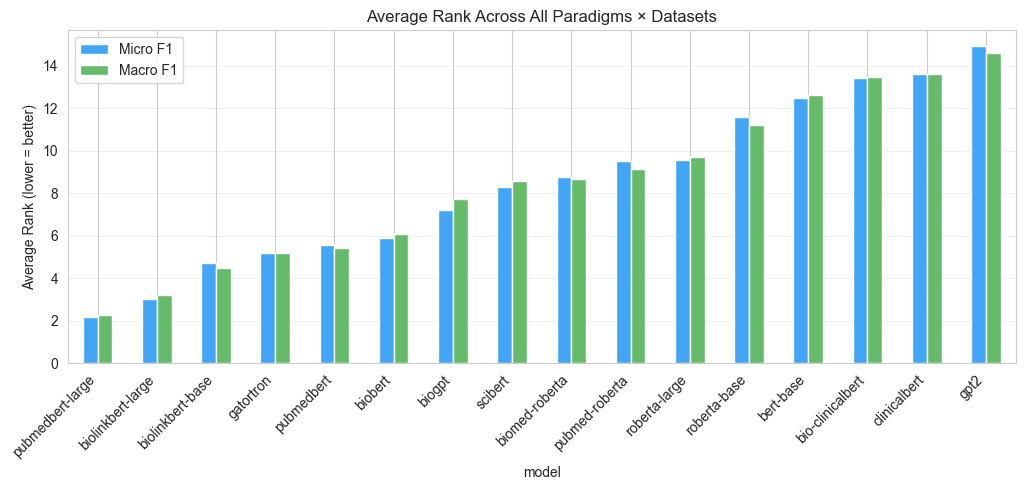

In [8]:
fig, ax = plt.subplots(figsize=(max(8, 0.4 * len(avg_ranks) + 4), 5))
avg_ranks.plot(kind='bar', ax=ax, color=['#42A5F5', '#66BB6A'])
ax.set_ylabel('Average Rank (lower = better)')
ax.set_title('Average Rank Across All Paradigms × Datasets')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.legend(['Micro F1', 'Macro F1'], loc='best')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('cross_corpora_avg_rank.png', dpi=150)
plt.show()

## 3. All-pairs significance matrix

Runs the §1 test for every directed paradigm pair `(A, B)` and both
metrics. Each cell reports how many `(model, dataset)` comparisons
are significant at BH p < 0.05 when the row paradigm is the baseline
(A) and the column paradigm is the comparison (B).

The matrix is **not** symmetric — the test is one-sided `B > A`, so
`(A=multiOriginal, B=multiTomek)` and `(A=multiTomek, B=multiOriginal)`
answer different questions and will typically disagree.

In [9]:
def _all_pairs_counts(metrics=('micro_f1', 'macro_f1')):
    rows = []
    for a_name in paradigm_names:
        for b_name in paradigm_names:
            if a_name == b_name:
                continue
            df_a, df_b = paradigms[a_name], paradigms[b_name]
            for metric in metrics:
                if metric not in df_a.columns or metric not in df_b.columns:
                    continue
                tbl = build_sig_table(df_a, df_b, metric)
                if tbl.empty:
                    continue
                rows.append({
                    'A': a_name, 'B': b_name, 'metric': metric,
                    'n_tested': int(tbl['wilcoxon_p'].notna().sum()),
                    'n_sig': int(tbl['significant_bh'].sum()),
                    'mean_delta': float(tbl['delta'].mean()),
                })
    return pd.DataFrame(rows)


all_pairs = _all_pairs_counts()
print(f'Computed {len(all_pairs)} (A, B, metric) comparisons.')
all_pairs.sort_values(['metric', 'n_sig'], ascending=[True, False]).reset_index(drop=True)

/Users/basel.alshaikhdeeb/medre-bench/.venv/lib/python3.11/site-packages/scipy/stats/_wilcoxon.py:199: UserWarning: Sample size too small for normal approximation.
  temp = _wilcoxon_iv(x, y, zero_method, correction, alternative, method, axis)
/Users/basel.alshaikhdeeb/medre-bench/.venv/lib/python3.11/site-packages/scipy/stats/_wilcoxon.py:199: UserWarning: Sample size too small for normal approximation.
  temp = _wilcoxon_iv(x, y, zero_method, correction, alternative, method, axis)
/Users/basel.alshaikhdeeb/medre-bench/.venv/lib/python3.11/site-packages/scipy/stats/_wilcoxon.py:199: UserWarning: Sample size too small for normal approximation.
  temp = _wilcoxon_iv(x, y, zero_method, correction, alternative, method, axis)
/Users/basel.alshaikhdeeb/medre-bench/.venv/lib/python3.11/site-packages/scipy/stats/_wilcoxon.py:199: UserWarning: Sample size too small for normal approximation.
  temp = _wilcoxon_iv(x, y, zero_method, correction, alternative, method, axis)
/Users/basel.alshaikhdee

Computed 60 (A, B, metric) comparisons.


,A,B,metric,n_tested,n_sig,mean_delta
0,aggregate_binary,BinaryTomek,macro_f1,112,109,0.116785
1,aggregate_multiclass,BinaryTomek,macro_f1,112,108,0.154081
2,aggregate_binary,BinaryOriginal,macro_f1,112,106,0.114267
3,aggregate_multiclass,BinaryOriginal,macro_f1,112,105,0.151562
4,multiTomek,BinaryOriginal,macro_f1,128,103,0.128239
5,multiOriginal,BinaryTomek,macro_f1,128,95,0.104447
6,multiTomek,BinaryTomek,macro_f1,128,94,0.127612
7,multiOriginal,BinaryOriginal,macro_f1,128,91,0.105074
8,aggregate_multiclass,multiOriginal,macro_f1,112,76,0.032335
9,aggregate_multiclass,multiTomek,macro_f1,112,71,0.007556


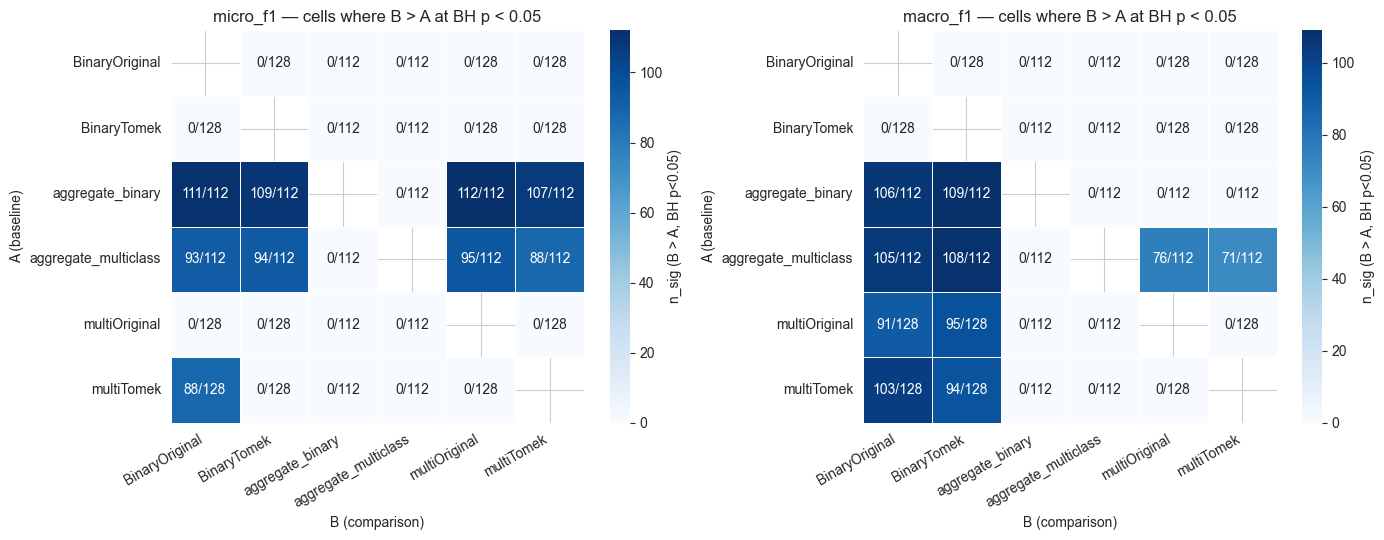

In [10]:
# One heatmap per metric. Rows = A (baseline), cols = B (comparison).
# Each cell is 'n_sig / n_tested' at BH p < 0.05.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, metric in zip(axes, ['micro_f1', 'macro_f1']):
    sub = all_pairs[all_pairs['metric'] == metric]
    if sub.empty:
        ax.set_axis_off()
        ax.set_title(f'{metric} — no data')
        continue
    piv_sig = sub.pivot(index='A', columns='B', values='n_sig')
    piv_tot = sub.pivot(index='A', columns='B', values='n_tested')
    piv_sig = piv_sig.reindex(index=paradigm_names, columns=paradigm_names)
    piv_tot = piv_tot.reindex(index=paradigm_names, columns=paradigm_names)
    annot = piv_sig.copy().astype(object)
    for i in piv_sig.index:
        for j in piv_sig.columns:
            v, t = piv_sig.at[i, j], piv_tot.at[i, j]
            annot.at[i, j] = '' if pd.isna(v) else f'{int(v)}/{int(t)}'
    sns.heatmap(piv_sig.fillna(0), annot=annot.values, fmt='',
                cmap='Blues', cbar_kws={'label': 'n_sig (B > A, BH p<0.05)'},
                linewidths=0.4, linecolor='white',
                mask=piv_sig.isna(), ax=ax)
    ax.set_title(f'{metric} — cells where B > A at BH p < 0.05')
    ax.set_xlabel('B (comparison)')
    ax.set_ylabel('A (baseline)')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.savefig('cross_corpora_all_pairs_sig.png', dpi=150, bbox_inches='tight')
plt.show()

### Notes

- Ranks are computed *per `(paradigm, dataset)` cell*, so a model that
  only appears in some paradigms isn't penalized for the ones it's
  absent from — its average is taken over the cells where it ran.
- The one-sided Wilcoxon in §1 answers "is B reliably better than
  A at this cell?". If you want the opposite direction, swap the
  dropdowns rather than re-coding the test.
- BH-FDR correction is applied **per paradigm-pair**, not pooled
  across pairs — so §3's counts come from independent corrections.
  Reading one row of the §3 matrix: "how many (model, dataset)
  cells improve when I switch from the row paradigm to each column
  paradigm?".